# 12 — Preparación del pipeline multiclase

**Responsable:** Edwin
**Dataset:** `data/processed/dataset_limpio.csv`
**Semana 6 — Clasificación multiclase**

Objetivo: adaptar el pipeline de la clasificación binaria (Normal vs. Ataque) para trabajar directamente con
`Attack_type` (12 clases), manteniendo las mismas decisiones de preparación de datos, y dejar listo el conjunto
Train/Test que se usará para entrenar el Random Forest multiclase (`13_random_forest_multiclase.ipynb`).

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 1. Carga del dataset limpio

Se usa el mismo archivo que en la clasificación binaria (`07`, `08`, `11`): 117.922 filas y 37 columnas, sin nulos.
Las variables redundantes (46) y la constante ya fueron eliminadas en `03_dataset_limpio.ipynb`.

In [2]:
DATA_PATH = "../data/processed/dataset_limpio.csv"
df = pd.read_csv(DATA_PATH, index_col=0)

print("Shape:", df.shape)
print("Nulos totales:", df.isna().sum().sum())
assert df.shape == (117922, 37), "Se esperaba la misma versión de dataset_limpio usada en la clasificación binaria."
assert df.isna().sum().sum() == 0

Shape: (117922, 37)
Nulos totales: 0


### Índice no único

El índice guardado en `dataset_limpio.csv` proviene del CSV original, que reinicia la numeración en cada tipo de tráfico,
por lo que **no es único** (hay valores repetidos entre clases). Para poder rastrear cada flujo en el análisis de errores
se crea un identificador único `row_id` = posición de la fila en `dataset_limpio.csv` (0 … 117.921).

In [3]:
print("Índice original único:", df.index.is_unique, "| valores repetidos:", df.index.duplicated().sum())

df = df.reset_index(drop=True)
df.index.name = "row_id"
assert df.index.is_unique

Índice original único: False | valores repetidos: 27833


## 2. Variable objetivo multiclase

**Cambio principal respecto al pipeline binario.** En binario se construía:

```python
NORMAL_CLASSES = {"MQTT_Publish", "Thing_Speak", "Wipro_bulb"}
y_bin = (~df["Attack_type"].isin(NORMAL_CLASSES)).astype(int)
```

Ahora la variable objetivo es directamente `Attack_type`. Se conservan las etiquetas como texto
(Random Forest las acepta y la matriz de confusión queda legible).

In [4]:
TARGET = "Attack_type"
y = df[TARGET].copy()

print("Número de clases:", y.nunique())
assert y.nunique() == 12
sorted(y.unique())

Número de clases: 12


['ARP_poisioning',
 'DDOS_Slowloris',
 'DOS_SYN_Hping',
 'MQTT_Publish',
 'Metasploit_Brute_Force_SSH',
 'NMAP_FIN_SCAN',
 'NMAP_OS_DETECTION',
 'NMAP_TCP_scan',
 'NMAP_UDP_SCAN',
 'NMAP_XMAS_TREE_SCAN',
 'Thing_Speak',
 'Wipro_bulb']

## 3. Selección de características

Se mantienen exactamente las mismas decisiones del modelo binario seleccionado (Random Forest, `08_comparacion_modelos.ipynb`):

- **Se excluyen las variables leaky:** `id.orig_p`, `id.resp_p`, `proto`, `service` (puertos, protocolo y servicio identifican casi directamente el tipo de tráfico).
- **Se excluye `Attack_type`** de X (es la variable objetivo).
- **Se conserva `flow_duration`:** el modelo binario de referencia la utiliza; el experimento sin ella (`10_analisis_random_forest.ipynb`) fue un análisis de sensibilidad, no un cambio de pipeline.
- **No se aplica escalamiento:** Random Forest es insensible a la escala.

In [5]:
LEAKY = ["id.orig_p", "id.resp_p", "proto", "service"]

X = df.drop(columns=[TARGET] + LEAKY)
FEATURES = list(X.columns)

print("Número de features:", len(FEATURES))
assert len(FEATURES) == 32
assert all(X.dtypes.apply(pd.api.types.is_numeric_dtype)), "Todas las features deben ser numéricas (sin encoding necesario)."
FEATURES

Número de features: 32


['flow_duration',
 'fwd_pkts_tot',
 'bwd_pkts_tot',
 'fwd_data_pkts_tot',
 'flow_pkts_per_sec',
 'down_up_ratio',
 'fwd_header_size_max',
 'bwd_header_size_max',
 'flow_FIN_flag_count',
 'flow_SYN_flag_count',
 'flow_RST_flag_count',
 'fwd_PSH_flag_count',
 'flow_ACK_flag_count',
 'fwd_URG_flag_count',
 'flow_CWR_flag_count',
 'fwd_pkts_payload.avg',
 'bwd_pkts_payload.min',
 'bwd_pkts_payload.avg',
 'flow_pkts_payload.min',
 'flow_pkts_payload.max',
 'flow_pkts_payload.tot',
 'flow_pkts_payload.avg',
 'flow_pkts_payload.std',
 'fwd_iat.std',
 'fwd_subflow_bytes',
 'fwd_bulk_bytes',
 'active.std',
 'idle.tot',
 'idle.std',
 'fwd_init_window_size',
 'bwd_init_window_size',
 'fwd_last_window_size']

## 4. Distribución de las 12 clases

In [6]:
dist = pd.DataFrame({
    "registros": y.value_counts(),
    "porcentaje": (y.value_counts(normalize=True) * 100).round(3),
})
dist

,registros,porcentaje
Attack_type,,
DOS_SYN_Hping,90089,76.397
Thing_Speak,7654,6.491
ARP_poisioning,7625,6.466
MQTT_Publish,4142,3.512
NMAP_UDP_SCAN,2584,2.191
NMAP_XMAS_TREE_SCAN,2010,1.705
NMAP_OS_DETECTION,2000,1.696
NMAP_TCP_scan,1002,0.850
DDOS_Slowloris,533,0.452


In [7]:
ratio = dist["registros"].max() / dist["registros"].min()
print(f"Clase mayoritaria: {dist.index[0]} ({dist['registros'].iloc[0]:,} registros)")
print(f"Clase minoritaria: {dist.index[-1]} ({dist['registros'].iloc[-1]:,} registros)")
print(f"Ratio de desbalance (mayor / menor): {ratio:,.0f} : 1")
print(f"Porcentaje de DOS_SYN_Hping sobre el total: {dist.loc['DOS_SYN_Hping', 'porcentaje']:.2f} %")

Clase mayoritaria: DOS_SYN_Hping (90,089 registros)
Clase minoritaria: NMAP_FIN_SCAN (28 registros)
Ratio de desbalance (mayor / menor): 3,217 : 1
Porcentaje de DOS_SYN_Hping sobre el total: 76.40 %


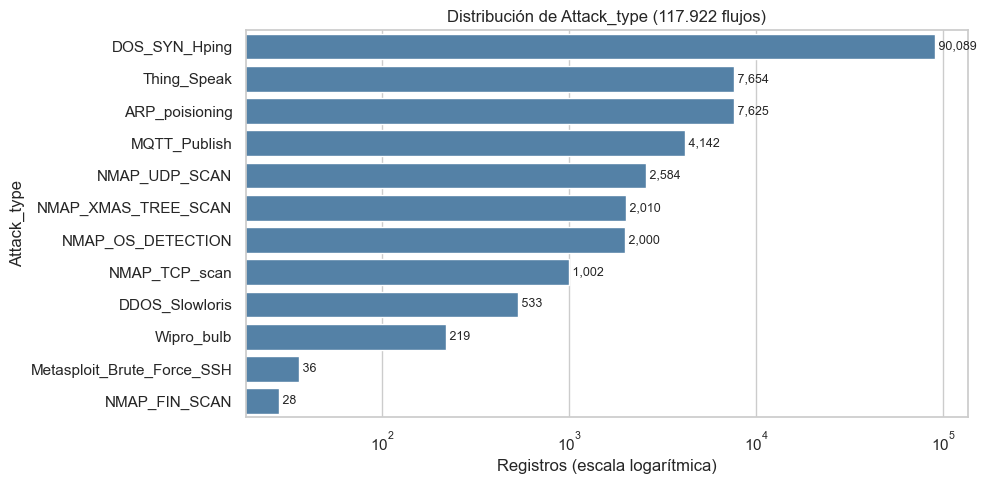

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=dist["registros"], y=dist.index, ax=ax, color="steelblue")
ax.set_xscale("log")
ax.set_xlabel("Registros (escala logarítmica)")
ax.set_ylabel("Attack_type")
ax.set_title("Distribución de Attack_type (117.922 flujos)")
for i, v in enumerate(dist["registros"]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 5. División Train/Test estratificada por las 12 clases

**Segundo cambio respecto al pipeline binario:** se estratifica con `stratify=y` (12 clases) en lugar de `stratify=y_bin`.
Se mantienen 80/20 y `random_state=42`.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (94337, 32) | X_test: (23585, 32)
y_train: (94337,) | y_test: (23585,)


## 6. Verificación de la representación de las clases en Train y Test

In [10]:
rep = pd.DataFrame({
    "total": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
})
rep["% total"] = (rep["total"] / rep["total"].sum() * 100).round(3)
rep["% train"] = (rep["train"] / rep["train"].sum() * 100).round(3)
rep["% test"] = (rep["test"] / rep["test"].sum() * 100).round(3)
rep["dif. pp (train-test)"] = (rep["% train"] - rep["% test"]).round(3)
rep = rep.sort_values("total", ascending=False)
rep

,total,train,test,% total,% train,% test,dif. pp (train-test)
Attack_type,,,,,,,
DOS_SYN_Hping,90089,72071,18018,76.397,76.397,76.396,0.001
Thing_Speak,7654,6123,1531,6.491,6.491,6.491,0.000
ARP_poisioning,7625,6100,1525,6.466,6.466,6.466,0.000
MQTT_Publish,4142,3314,828,3.512,3.513,3.511,0.002
NMAP_UDP_SCAN,2584,2067,517,2.191,2.191,2.192,-0.001
NMAP_XMAS_TREE_SCAN,2010,1608,402,1.705,1.705,1.704,0.001
NMAP_OS_DETECTION,2000,1600,400,1.696,1.696,1.696,0.000
NMAP_TCP_scan,1002,802,200,0.850,0.850,0.848,0.002
DDOS_Slowloris,533,426,107,0.452,0.452,0.454,-0.002


In [11]:
assert set(y_train.unique()) == set(y.unique()), "Falta alguna clase en Train"
assert set(y_test.unique()) == set(y.unique()), "Falta alguna clase en Test"
assert X_train.index.intersection(X_test.index).empty, "Train y Test comparten índices"
assert len(X_train) + len(X_test) == len(X)

print("Las 12 clases están presentes en Train y Test.")
print("Máxima diferencia de proporción train vs test:", rep["dif. pp (train-test)"].abs().max(), "pp")

Las 12 clases están presentes en Train y Test.
Máxima diferencia de proporción train vs test: 0.002 pp


### Comparación con la estratificación binaria

Para justificar el cambio, se repite el split usando la estratificación del pipeline binario (`stratify=y_bin`)
y se compara cuántas muestras de cada clase quedan en Test.

In [12]:
NORMAL_CLASSES = {"MQTT_Publish", "Thing_Speak", "Wipro_bulb"}
y_bin = (~y.isin(NORMAL_CLASSES)).astype(int)

_, _, _, y_test_binstrat = train_test_split(
    X, y, test_size=0.20, stratify=y_bin, random_state=RANDOM_STATE
)

comp = pd.DataFrame({
    "test esperado (20%)": (rep["total"] * 0.20).round(1),
    "test stratify=y (multiclase)": rep["test"],
    "test stratify=y_bin (binario)": y_test_binstrat.value_counts(),
})
comp

,test esperado (20%),test stratify=y (multiclase),test stratify=y_bin (binario)
Attack_type,,,
DOS_SYN_Hping,18017.8,18018,17893
Thing_Speak,1530.8,1531,1564
ARP_poisioning,1525.0,1525,1542
MQTT_Publish,828.4,828,792
NMAP_UDP_SCAN,516.8,517,551
NMAP_XMAS_TREE_SCAN,402.0,402,451
NMAP_OS_DETECTION,400.0,400,409
NMAP_TCP_scan,200.4,200,210
DDOS_Slowloris,106.6,107,116


Con la estratificación binaria, las clases minoritarias quedan representadas al azar (por ejemplo `NMAP_FIN_SCAN`
queda con 4 muestras en Test en lugar de las ~6 esperadas, como se observó en `11_analisis_errores.ipynb`).
Con `stratify=y` cada clase conserva su proporción.

## 7. Dificultades por el desbalance y los duplicados

### 7.1 Clases con muy pocas muestras en Test

In [13]:
pocas = rep[rep["test"] < 50][["total", "train", "test"]]
pocas

,total,train,test
Attack_type,,,
Wipro_bulb,219,175,44
Metasploit_Brute_Force_SSH,36,29,7
NMAP_FIN_SCAN,28,22,6


`Metasploit_Brute_Force_SSH` y `NMAP_FIN_SCAN` tienen menos de 10 muestras en Test: **un solo error cambia su recall
entre ~14 y ~17 puntos porcentuales**. Sus métricas individuales serán muy inestables y deben interpretarse con cuidado.

In [14]:
for clase in pocas.index:
    n = rep.loc[clase, "test"]
    print(f"{clase:<28} n_test={n:>4} -> 1 error = {100 / n:5.1f} pp de recall")

Wipro_bulb                   n_test=  44 -> 1 error =   2.3 pp de recall
Metasploit_Brute_Force_SSH   n_test=   7 -> 1 error =  14.3 pp de recall
NMAP_FIN_SCAN                n_test=   6 -> 1 error =  16.7 pp de recall


### 7.2 Duplicados exactos al eliminar las variables leaky

`dataset_limpio.csv` no tiene filas duplicadas con todas sus columnas, pero al eliminar puertos, protocolo y servicio
muchos flujos quedan **idénticos en las 32 features**.

In [15]:
dup_mask = X.duplicated(keep=False)
print(f"Filas duplicadas en X (sin contar la primera aparición): {X.duplicated().sum():,} de {len(X):,} "
      f"({X.duplicated().mean() * 100:.1f} %)")

unicos = pd.DataFrame({
    "registros": y.value_counts(),
    "filas únicas en X": pd.concat([X, y], axis=1).drop_duplicates().groupby(TARGET).size(),
})
unicos["% duplicado"] = ((1 - unicos["filas únicas en X"] / unicos["registros"]) * 100).round(1)
unicos.sort_values("registros", ascending=False)

Filas duplicadas en X (sin contar la primera aparición): 100,034 de 117,922 (84.8 %)


,registros,filas únicas en X,% duplicado
Attack_type,,,
DOS_SYN_Hping,90089,57,99.9
Thing_Speak,7654,7487,2.2
ARP_poisioning,7625,5035,34.0
MQTT_Publish,4142,4141,0.0
NMAP_UDP_SCAN,2584,193,92.5
NMAP_XMAS_TREE_SCAN,2010,80,96.0
NMAP_OS_DETECTION,2000,75,96.2
NMAP_TCP_scan,1002,44,95.6
DDOS_Slowloris,533,533,0.0


El caso más extremo es `DOS_SYN_Hping`: sus ~90.000 flujos se reducen a unas pocas decenas de combinaciones únicas
(son paquetes SYN de flood prácticamente iguales). Consecuencia: **una gran parte del Test tiene una copia exacta en Train**,
lo que hace que las métricas sean optimistas para esas clases.

In [16]:
train_keys = set(pd.util.hash_pandas_object(X_train, index=False))
test_hash = pd.util.hash_pandas_object(X_test, index=False)
en_train = test_hash.isin(train_keys)

print(f"Filas de Test con una fila idéntica en Train: {en_train.sum():,} de {len(X_test):,} ({en_train.mean() * 100:.1f} %)")

fuga = pd.DataFrame({
    "n_test": y_test.value_counts(),
    "test con copia en train": y_test[en_train.values].value_counts(),
}).fillna(0).astype(int)
fuga["%"] = (fuga["test con copia en train"] / fuga["n_test"] * 100).round(1)
fuga.sort_values("n_test", ascending=False)

Filas de Test con una fila idéntica en Train: 20,071 de 23,585 (85.1 %)


,n_test,test con copia en train,%
Attack_type,,,
DOS_SYN_Hping,18018,18016,100.0
Thing_Speak,1531,46,3.0
ARP_poisioning,1525,533,35.0
MQTT_Publish,828,1,0.1
NMAP_UDP_SCAN,517,480,92.8
NMAP_XMAS_TREE_SCAN,402,399,99.3
NMAP_OS_DETECTION,400,397,99.2
NMAP_TCP_scan,200,193,96.5
DDOS_Slowloris,107,0,0.0


### 7.3 Flujos idénticos con etiquetas distintas

Algunas combinaciones exactas de features aparecen con más de una etiqueta. Ningún modelo puede clasificar
correctamente todas esas filas, lo que impone un pequeño techo al desempeño.

In [17]:
keys = pd.util.hash_pandas_object(X, index=False)
grupos = pd.DataFrame({"key": keys.values, TARGET: y.values}, index=X.index)
n_etiquetas = grupos.groupby("key")[TARGET].nunique()
conflictivos = n_etiquetas[n_etiquetas > 1].index

filas_conf = grupos[grupos["key"].isin(conflictivos)]
print("Combinaciones de features con más de una etiqueta:", len(conflictivos))
print("Filas afectadas:", len(filas_conf))

pares = (filas_conf.groupby("key")[TARGET]
         .apply(lambda s: " / ".join(sorted(s.unique())))
         .value_counts()
         .rename("combinaciones"))
pares.to_frame()

Combinaciones de features con más de una etiqueta: 14
Filas afectadas: 3809


,combinaciones
Attack_type,
ARP_poisioning / NMAP_UDP_SCAN,5
ARP_poisioning / Thing_Speak,3
ARP_poisioning / NMAP_UDP_SCAN / Thing_Speak,2
NMAP_UDP_SCAN / Thing_Speak,2
Metasploit_Brute_Force_SSH / NMAP_UDP_SCAN,1
ARP_poisioning / DDOS_Slowloris / Thing_Speak,1


In [18]:
afectadas = pd.DataFrame({
    "filas en combinaciones ambiguas": filas_conf[TARGET].value_counts(),
    "total clase": y.value_counts(),
}).dropna().astype(int)
afectadas["% de la clase"] = (afectadas.iloc[:, 0] / afectadas["total clase"] * 100).round(1)
afectadas.sort_values("filas en combinaciones ambiguas", ascending=False)

,filas en combinaciones ambiguas,total clase,% de la clase
Attack_type,,,
NMAP_UDP_SCAN,2235,2584,86.5
ARP_poisioning,1559,7625,20.4
Thing_Speak,13,7654,0.2
Metasploit_Brute_Force_SSH,1,36,2.8
DDOS_Slowloris,1,533,0.2


`NMAP_UDP_SCAN` y `ARP_poisioning` son las clases más afectadas: una parte importante de sus flujos es **indistinguible**
(en las 32 features) de flujos de otras clases. Esto anticipa confusiones entre `ARP_poisioning`, `NMAP_UDP_SCAN` y
`Thing_Speak` en el modelo multiclase, y es coherente con que `ARP_poisioning` concentrara los falsos negativos en binario.

### Decisión

Se **mantienen las 117.922 filas** (sin deduplicar) para conservar la comparabilidad directa con los resultados de la
clasificación binaria, que se obtuvieron con este mismo dataset. Los duplicados se documentan como limitación y se
recomienda evaluar en una semana posterior una variante deduplicada o una partición por grupos.

## 8. Exportar el conjunto para el Random Forest multiclase

Se guardan los conjuntos en `data/processed/multiclase/` conservando el índice original del dataset,
para que el análisis de errores pueda rastrear cada flujo.

In [19]:
OUT_DIR = "../data/processed/multiclase"
os.makedirs(OUT_DIR, exist_ok=True)

X_train.to_csv(os.path.join(OUT_DIR, "X_train.csv"))
X_test.to_csv(os.path.join(OUT_DIR, "X_test.csv"))
y_train.to_csv(os.path.join(OUT_DIR, "y_train.csv"))
y_test.to_csv(os.path.join(OUT_DIR, "y_test.csv"))

meta = {
    "source": "data/processed/dataset_limpio.csv",
    "target": TARGET,
    "classes": sorted(y.unique()),
    "features": FEATURES,
    "excluded_leaky": LEAKY,
    "test_size": 0.20,
    "stratify": TARGET,
    "random_state": RANDOM_STATE,
    "n_train": len(X_train),
    "n_test": len(X_test),
}
with open(os.path.join(OUT_DIR, "feature_list.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

sorted(os.listdir(OUT_DIR))

['X_test.csv', 'X_train.csv', 'feature_list.json', 'y_test.csv', 'y_train.csv']

### Verificación de la recarga

Cómo debe cargar Daniel los datos en `13_random_forest_multiclase.ipynb`:

In [20]:
X_train_r = pd.read_csv(os.path.join(OUT_DIR, "X_train.csv"), index_col=0)
X_test_r = pd.read_csv(os.path.join(OUT_DIR, "X_test.csv"), index_col=0)
y_train_r = pd.read_csv(os.path.join(OUT_DIR, "y_train.csv"), index_col=0)[TARGET]
y_test_r = pd.read_csv(os.path.join(OUT_DIR, "y_test.csv"), index_col=0)[TARGET]

assert X_train_r.shape == X_train.shape and X_test_r.shape == X_test.shape
assert list(X_train_r.columns) == FEATURES
assert y_train_r.nunique() == 12 and y_test_r.nunique() == 12
assert (X_test_r.index == X_test.index).all()
print("Recarga verificada:", X_train_r.shape, X_test_r.shape)

Recarga verificada: (94337, 32) (23585, 32)


## 9. Resumen

| Aspecto | Binario | Multiclase |
|---|---|---|
| Variable objetivo | `y_bin` (0 = Normal, 1 = Ataque) | `Attack_type` (12 clases) |
| Estratificación | `stratify=y_bin` | `stratify=y` |
| Variables leaky | Excluidas (4) | Excluidas (4) |
| Features | 32 numéricas | Las mismas 32 |
| Escalamiento | No (árboles) | No (árboles) |
| Split | 80/20, `random_state=42` | 80/20, `random_state=42` |
| Métricas recomendadas | F1, F1-Macro, PR-AUC | F1-Macro, F1-Weighted, Precision/Recall macro, métricas por clase |

Las conclusiones y respuestas a las preguntas de la semana están en `docs/preparacion_multiclase.md`.